# Artificial Neural Networks (AIC 380)
**Student Name:** Abdullah Ghaffar  
**Registration No:** FA23-BAI-059  

---
## Lab 04 (Manual Lab 06): Implementation of Self-Organizing Map (SOM) in Python

### Objective:
Understanding Kohonen Self-Organizing Maps (SOM): unsupervised competitive learning, Best Matching Unit (BMU) selection via Euclidean distance, Gaussian neighborhood adaptation, topological 2D projection, and clustering.


### Activities 1 & 2: SOM Architecture and Online Training Algorithm


In [1]:
import numpy as np
from sklearn import datasets
from sklearn.preprocessing import MinMaxScaler
import matplotlib.pyplot as plt

# Activity 1: Data Pre-processing
iris = datasets.load_iris()
X = iris.data
scaler = MinMaxScaler()
X_scaled = scaler.fit_transform(X)
print("Data scaled successfully. Shape:", X_scaled.shape)

# Activity 2: Implementing SOM from Scratch
class SOM:
    def __init__(self, m, n, dim, learning_rate=0.5, sigma=None):
        self.m = m
        self.n = n
        self.dim = dim
        self.learning_rate = learning_rate
        self.sigma = sigma if sigma else max(m, n) / 2.0
        self.weights = np.random.rand(m, n, dim)

    def _find_bmu(self, x):
        distances = np.linalg.norm(self.weights - x, axis=-1)
        bmu_index = np.unravel_index(np.argmin(distances), (self.m, self.n))
        return bmu_index

    def _update_weights(self, x, bmu, iteration, max_iter):
        # Exponential decay of learning rate and sigma
        lr = self.learning_rate * np.exp(-iteration / max_iter)
        sig = self.sigma * np.exp(-iteration / max_iter)
        
        for i in range(self.m):
            for j in range(self.n):
                w = self.weights[i, j]
                dist = np.linalg.norm(np.array([i, j]) - np.array(bmu))
                if dist < sig:
                    influence = np.exp(- (dist ** 2) / (2 * (sig ** 2)))
                    self.weights[i, j] += influence * lr * (x - w)

    def train(self, X, num_iterations=100):
        for iteration in range(num_iterations):
            for x in X:
                bmu = self._find_bmu(x)
                self._update_weights(x, bmu, iteration, num_iterations)
        print(f"SOM training completed for {num_iterations} iterations.")

print("SOM class implemented.")


Data scaled successfully. Shape: (150, 4)
SOM class implemented.


### Activities 3, 4 & 5: Training, Visualization, and Cluster Assignment


SOM training completed for 100 iterations.


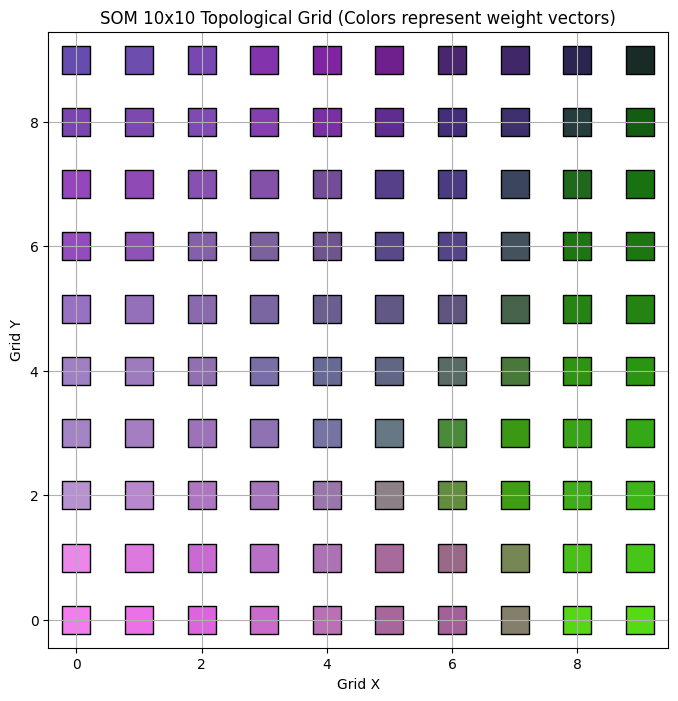

First 10 sample BMU coordinates:
[[3 8]
 [6 8]
 [6 9]
 [7 9]
 [3 9]
 [1 9]
 [4 9]
 [4 8]
 [8 9]
 [6 8]]


In [2]:
# Activity 3: Training the SOM
som = SOM(m=10, n=10, dim=4, learning_rate=0.5)
som.train(X_scaled, num_iterations=100)

# Activity 4: Visualization of SOM Grid Weights
plt.figure(figsize=(8, 8))
for i in range(som.m):
    for j in range(som.n):
        # Map first 3 dimensions to RGB color
        color_rgb = np.clip(som.weights[i, j, :3], 0, 1)
        plt.scatter(j, i, color=color_rgb, marker='s', s=400, edgecolors='k')
plt.title('SOM 10x10 Topological Grid (Colors represent weight vectors)')
plt.xlabel('Grid X')
plt.ylabel('Grid Y')
plt.grid(True)
plt.show()

# Activity 5: Clustering with SOM
def get_cluster_labels(som, X):
    cluster_labels = []
    for x in X:
        bmu = som._find_bmu(x)
        cluster_labels.append(bmu)
    return np.array(cluster_labels)

bmu_coords = get_cluster_labels(som, X_scaled)
print("First 10 sample BMU coordinates:")
print(bmu_coords[:10])


### Graded Lab Task 1: SOM on Real-World Dataset with Comprehensive Evaluation


SOM training completed for 150 iterations.


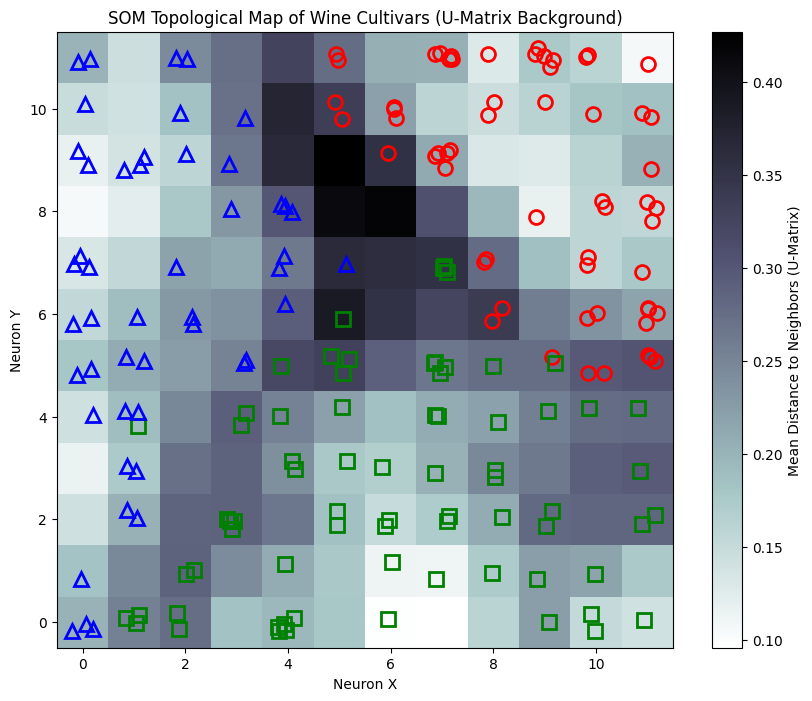

SOM successfully separated the 3 distinct classes into clustered topological regions.


In [3]:
# We train SOM on Wine / Banknote Authentication style dataset from sklearn
from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler

wine = load_wine()
X_wine = wine.data
y_wine = wine.target

# Standardize features
scaler_wine = StandardScaler()
X_wine_norm = scaler_wine.fit_transform(X_wine)

# MinMax scale to [0, 1] for stable SOM training
minmax = MinMaxScaler()
X_wine_scaled = minmax.fit_transform(X_wine_norm)

# Instantiate 12x12 SOM for 13-dimensional input
som_wine = SOM(m=12, n=12, dim=X_wine.shape[1], learning_rate=0.6)
som_wine.train(X_wine_scaled, num_iterations=150)

# Map every data point to BMU on grid
bmus = [som_wine._find_bmu(x) for x in X_wine_scaled]

# Plot Cluster Distribution with class labels
plt.figure(figsize=(10, 8))
# Compute U-Matrix (distance to neighboring neurons)
u_matrix = np.zeros((som_wine.m, som_wine.n))
for i in range(som_wine.m):
    for j in range(som_wine.n):
        neighbors = []
        for di in [-1, 0, 1]:
            for dj in [-1, 0, 1]:
                ni, nj = i + di, j + dj
                if 0 <= ni < som_wine.m and 0 <= nj < som_wine.n and not (di == 0 and dj == 0):
                    neighbors.append(np.linalg.norm(som_wine.weights[i, j] - som_wine.weights[ni, nj]))
        u_matrix[i, j] = np.mean(neighbors)

plt.imshow(u_matrix, cmap='bone_r', origin='lower')
plt.colorbar(label='Mean Distance to Neighbors (U-Matrix)')

markers = ['o', 's', '^']
colors = ['red', 'green', 'blue']
for idx, (bmu, label) in enumerate(zip(bmus, y_wine)):
    plt.plot(bmu[1] + np.random.uniform(-0.2, 0.2), 
             bmu[0] + np.random.uniform(-0.2, 0.2), 
             markers[label], markerfacecolor='None',
             markeredgecolor=colors[label], markersize=10, markeredgewidth=2)

plt.title('SOM Topological Map of Wine Cultivars (U-Matrix Background)')
plt.xlabel('Neuron X')
plt.ylabel('Neuron Y')
plt.show()

print("SOM successfully separated the 3 distinct classes into clustered topological regions.")
